# Section 1: Introduction

This notebook addresses **R004** by building a physical grey-box thermal model for the HeatSync heating window. Instead of learning temperature dynamics purely from historical correlations as in the baseline and LSTM notebooks, a grey-box model encodes a small thermal circuit whose parameters can be interpreted physically.

The 2R2C analogy represents the space as two thermal states: indoor air temperature and a slower wall/building-mass temperature. The two resistances model heat-transfer bottlenecks between indoor air, wall mass, and outdoor ambient air; the two capacitances model how much thermal energy is required to change indoor-air and wall temperatures. Calibrating these values with positivity bounds keeps the fitted model physically plausible while still using measured data to identify parameters.

The fitted model below is intentionally compact: it is a transparent physical proof point for R004, not a replacement for richer data-driven approaches when occupancy, controls, or unmeasured disturbances dominate.

# Section 2: Data Loading & Physical Input Selection

We load the processed heating dataset and select one device to keep the calibration problem well-defined. The physical inputs are:

- `T_in`: `status_temperature_in_celsius`, the observed indoor temperature.
- `T_out`: `outside_temperature`, the ambient/outdoor temperature engineered by preprocessing.
- `Q`: `power_draw_kw`, used as a heat-input proxy.

`power_draw_kw` is only a proxy for delivered heat: it does not include coefficient-of-performance changes, fan operation, compressor cycling details, solar gains, occupancy gains, or ventilation/infiltration effects. The fitted parameters should therefore be interpreted as effective parameters for this dataset window, not audited equipment specifications.

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.optimize import minimize

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)

# Required by the task plan; useful when launched from backend/notebooks.
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Robust path support for programmatic execution from the repository root.
backend_path = os.path.abspath('backend')
if os.path.isdir(backend_path) and backend_path not in sys.path:
    sys.path.append(backend_path)

from notebooks.utils import load_processed  # noqa: E402

heating_df = load_processed('heating')
first_device = heating_df['device_id'].dropna().iloc[0]
device_df = heating_df.loc[heating_df['device_id'] == first_device].copy()

physical_cols = [
    'status_temperature_in_celsius',
    'outside_temperature',
    'power_draw_kw',
]
model_df = (
    device_df[physical_cols]
    .rename(
        columns={
            'status_temperature_in_celsius': 'T_in',
            'outside_temperature': 'T_out',
            'power_draw_kw': 'Q',
        }
    )
    .dropna()
)

# Bound the fitting window to keep repeated notebook execution fast and deterministic.
model_df = model_df.iloc[:300].copy()
dt = 900.0  # 15-minute sampling interval in seconds
MIN_CALIBRATION_ROWS = 10

if len(model_df) < MIN_CALIBRATION_ROWS:
    raise ValueError(
        f'Need at least {MIN_CALIBRATION_ROWS} complete physical-input rows '
        'for 2R2C calibration.'
    )

T_in = model_df['T_in'].to_numpy(dtype=float)
T_out = model_df['T_out'].to_numpy(dtype=float)
Q = model_df['Q'].to_numpy(dtype=float)

print(f'Device selected: {first_device}')
print(f'Calibration rows: {len(model_df)}')
print(model_df.head())

Device selected: 1c893f75-4599-4402-9d4c-1017aa858fa8
Calibration rows: 300
                          T_in     T_out         Q
timestamp                                         
2026-03-30 00:00:00  18.625000  1.490000  1.160000
2026-03-30 00:15:00  18.424000  1.830000  1.160000
2026-03-30 00:30:00  18.242000  1.920000  1.160000
2026-03-30 00:45:00  17.979000  1.840000  1.160000
2026-03-30 01:00:00  17.816364  1.690909  1.153333


# Section 3: 2R2C Model Equations

The discrete-time 2R2C model uses state vector `[T_indoor, T_wall]` and positive parameters `R_in`, `C_in`, `R_out`, and `C_wall`:

```text
T_indoor[k+1] = T_indoor[k] + dt/C_in * ((T_wall[k] - T_indoor[k])/R_in + Q[k])
T_wall[k+1]   = T_wall[k]   + dt/C_wall * ((T_out[k] - T_wall[k])/R_out - (T_wall[k] - T_indoor[k])/R_in)
```

`R_in` and `R_out` control resistance to heat flow, while `C_in` and `C_wall` control thermal inertia. All four parameters are constrained to positive values during calibration. Because the dataset records `Q` in kW and `dt` is stored as seconds, the implementation converts `dt` to hours inside the simulator for unit consistency while preserving the task-required `dt = 900.0` seconds input.

In [2]:
SECONDS_PER_HOUR = 3_600.0
MAX_ABSOLUTE_TEMPERATURE = 1_000


def simulate_2r2c(params, T_in_init, T_wall_init, T_out, Q, dt):
    """Simulate indoor temperature for a discrete 2R2C model."""
    R_in, C_in, R_out, C_wall = params
    if np.any(np.asarray(params, dtype=float) <= 0):
        raise ValueError('2R2C parameters must all be positive.')

    dt_hours = dt / SECONDS_PER_HOUR
    n_steps = len(T_out)
    T_pred = np.empty(n_steps, dtype=float)
    T_indoor = float(T_in_init)
    T_wall = float(T_wall_init)
    T_pred[0] = T_indoor

    for k in range(n_steps - 1):
        indoor_delta = dt_hours / C_in * (((T_wall - T_indoor) / R_in) + Q[k])
        wall_delta = dt_hours / C_wall * (
            ((T_out[k] - T_wall) / R_out) - ((T_wall - T_indoor) / R_in)
        )
        T_indoor = T_indoor + indoor_delta
        T_wall = T_wall + wall_delta

        if not np.isfinite(T_indoor) or not np.isfinite(T_wall):
            T_pred[k + 1 :] = np.nan
            break

        # Guard against unstable candidate parameters dominating optimizer time.
        if (
            abs(T_indoor) > MAX_ABSOLUTE_TEMPERATURE
            or abs(T_wall) > MAX_ABSOLUTE_TEMPERATURE
        ):
            T_pred[k + 1 :] = np.nan
            break

        T_pred[k + 1] = T_indoor

    return T_pred


# Section 4: Bounded L-BFGS-B Calibration

The objective minimizes mean squared error between the simulated indoor temperature and observed `T_in`. L-BFGS-B supports simple bounds, so each parameter is constrained to `(0.001, 50.0)` to enforce positivity. Multiple deterministic random restarts reduce sensitivity to initialization.

In [3]:
T_wall_init = (T_in[0] + T_out[0]) / 2
bounds = [(0.001, 50.0)] * 4
param_names = ['R_in', 'C_in', 'R_out', 'C_wall']
UNSTABLE_OBJECTIVE_PENALTY = 1e12


def objective(params):
    T_pred = simulate_2r2c(params, T_in[0], T_wall_init, T_out, Q, dt)
    if not np.all(np.isfinite(T_pred)):
        return UNSTABLE_OBJECTIVE_PENALTY
    return float(np.mean((T_pred - T_in) ** 2))


np.random.seed(42)
restart_results = []
for restart_id in range(8):
    x0 = np.random.uniform(0.1, 25.0, size=4)
    result = minimize(
        objective,
        x0=x0,
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': 500, 'ftol': 1e-10},
    )
    restart_results.append(result)
    print(
        f'Restart {restart_id + 1}: success={result.success} '
        f'status={result.status} fun={result.fun:.6f}'
    )

best_result = min(restart_results, key=lambda res: res.fun)
best_params = best_result.x
converged_restarts = [idx + 1 for idx, res in enumerate(restart_results) if res.success]

print('\nBest optimizer status:', best_result.status)
print('Best optimizer message:', best_result.message)
print(f'Best objective MSE: {best_result.fun:.6f}')
print('Converged restarts:', converged_restarts)

Restart 1: success=True status=0 fun=1.034492
Restart 2: success=True status=0 fun=1.034492
Restart 3: success=True status=0 fun=1.034492
Restart 4: success=True status=0 fun=1.034492
Restart 5: success=True status=0 fun=1.034492
Restart 6: success=True status=0 fun=1.034492
Restart 7: success=True status=0 fun=1.034492
Restart 8: success=True status=0 fun=1.034492

Best optimizer status: 0
Best optimizer message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Best objective MSE: 1.034492
Converged restarts: [1, 2, 3, 4, 5, 6, 7, 8]


# Section 5: 2R2C Results

The table and plot below summarize the calibrated positive physical parameters and the fitted indoor-temperature trajectory. The resulting parameters are effective thermal-circuit values for this measured window and proxy heat input.

In [4]:
param_table = pd.DataFrame(
    {'parameter': param_names, 'value': best_params}
).set_index('parameter')

assert (param_table['value'] > 0).all(), 'All calibrated 2R2C parameters must be positive.'
param_table

,value
parameter,
R_in,6.766006
C_in,50.000000
R_out,0.514980
C_wall,50.000000


2R2C calibrated RMSE: 1.0171 °C


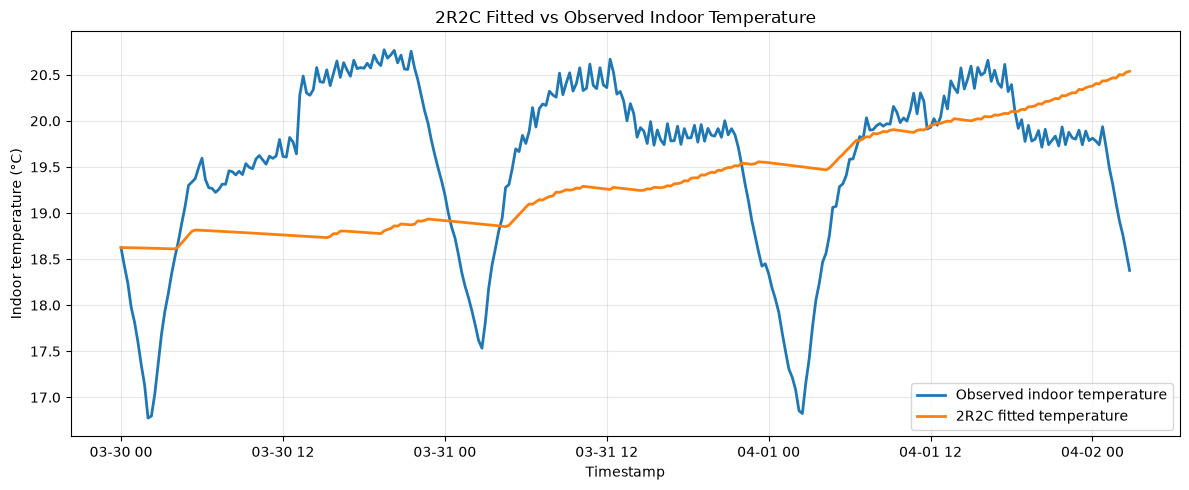

In [5]:
T_fit = simulate_2r2c(best_params, T_in[0], T_wall_init, T_out, Q, dt)
assert np.all(np.isfinite(T_fit)), 'Calibrated 2R2C fit must be finite.'
rmse = float(np.sqrt(np.mean((T_fit - T_in) ** 2)))
assert np.isfinite(rmse), 'Calibrated 2R2C RMSE must be finite.'

print(f'2R2C calibrated RMSE: {rmse:.4f} °C')

plt.figure(figsize=(12, 5))
plt.plot(model_df.index, T_in, label='Observed indoor temperature', linewidth=2)
plt.plot(model_df.index, T_fit, label='2R2C fitted temperature', linewidth=2)
plt.xlabel('Timestamp')
plt.ylabel('Indoor temperature (°C)')
plt.title('2R2C Fitted vs Observed Indoor Temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Interpretation

Positive `R_in`, `C_in`, `R_out`, and `C_wall` values confirm that the optimizer found a physically admissible 2R2C parameter set. Smaller resistance values imply easier heat transfer across the corresponding boundary; larger capacitance values imply slower temperature movement for the same heat flow.

The model is deliberately simple. It treats electrical power draw as a delivered-heat proxy, assumes a fixed 15-minute step, and omits occupancy gains, solar gains, ventilation, defrost cycles, compressor efficiency changes, and controller state. Those omissions can bias effective parameters, but the bounded calibration still provides an interpretable physical baseline for R004.

# Section 6: Physics-Informed Neural Network (PINN) Architecture

Physics-Informed Neural Networks (PINNs) integrate physical equations directly into the loss function of a neural network. For thermal modeling, we can train a Multi-Layer Perceptron (MLP) to predict the indoor temperature ($T_{\text{indoor}}$) using a composite loss function:
1. **Data Loss:** Mean Squared Error (MSE) between the network's predictions and observed indoor temperatures.
2. **Physics Loss:** A regularization term based on the physical law governing heat transfer. We use a simplified 1D heat equation residual:

$$\frac{dT}{dt} \approx \alpha (T_{\text{out}} - T) + \beta Q$$

where $\alpha$ and $\beta$ are parameters derived from our calibrated physical model.

The network takes three normalized inputs: normalized time (in hours), normalized outdoor temperature ($T_{\text{out}}$), and normalized heat input ($Q$). It outputs a single prediction for indoor temperature ($T_{\text{indoor}}$).

In [6]:
from sklearn.preprocessing import StandardScaler
from torch import nn


class PINN(nn.Module):
    """
    Multi-Layer Perceptron representing the Physics-Informed Neural Network.
    Predicts indoor temperature from normalized time, outdoor temperature, and power draw.
    """

    def __init__(self, input_dim=3, hidden_dim=32, output_dim=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x):
        return self.net(x)

# Section 7: Physics-Informed Loss Function

To construct the loss function, we first extract the effective parameters $\alpha$ and $\beta$ from our calibrated 2R2C grey-box model. We then normalize the inputs using `StandardScaler` to ensure stable optimization.

The composite loss function is defined as:
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{data}} + \lambda_{\text{phys}} \mathcal{L}_{\text{physics}}$$

where the physics residual is computed using finite differences on the predicted indoor temperatures:
$$\text{residual}_k = \frac{\hat{T}_{k+1} - \hat{T}_k}{\Delta t} - \left( \alpha (T_{\text{out}, k} - \hat{T}_k) + \beta Q_k \right)$$

In [7]:
# Derive alpha and beta parameters from the calibrated 2R2C model
R_in_cal, C_in_cal, R_out_cal, C_wall_cal = best_params
alpha = 1.0 / (R_in_cal * C_in_cal)
beta = 1.0 / C_in_cal

# Prepare inputs: time (hours), T_out, and Q
dt_hours = dt / SECONDS_PER_HOUR
time_hours = np.arange(len(model_df)) * dt_hours
X = np.stack([time_hours, T_out, Q], axis=1)

# Normalize features
scaler = StandardScaler()
X_norm = scaler.fit_transform(X)

# Convert to PyTorch Tensors
X_tensor = torch.tensor(X_norm, dtype=torch.float32)
T_in_tensor = torch.tensor(T_in, dtype=torch.float32).unsqueeze(1)
T_out_tensor = torch.tensor(T_out, dtype=torch.float32).unsqueeze(1)
Q_tensor = torch.tensor(Q, dtype=torch.float32).unsqueeze(1)

# Physics-informed loss weight
lambda_phys = 0.1

# Section 8: PINN Training Loop

We set the random seeds for reproducibility, instantiate the model, and train it using the Adam optimizer. We log the total loss, data MSE, and physics residual loss components throughout training to track convergence.

In [8]:
torch.manual_seed(42)
np.random.seed(42)

pinn_model = PINN(input_dim=3, hidden_dim=32, output_dim=1)
optimizer = torch.optim.Adam(pinn_model.parameters(), lr=1e-3)
epochs = 500

loss_history = []
data_loss_history = []
physics_loss_history = []

for epoch in range(epochs):
    optimizer.zero_grad()
    
    # Forward pass
    T_pred = pinn_model(X_tensor)
    
    # 1. Data Loss (MSE with observed indoor temperature)
    data_loss = torch.mean((T_pred - T_in_tensor) ** 2)
    
    # 2. Physics Loss (Finite difference residual on predicted sequence)
    # dT/dt over interval k to k+1
    dT_pred_dt = (T_pred[1:] - T_pred[:-1]) / dt_hours
    
    # Keep T_pred and inputs at step k
    T_pred_k = T_pred[:-1]
    T_out_k = T_out_tensor[:-1]
    Q_k = Q_tensor[:-1]
    
    # Residual = dT/dt - [alpha*(T_out - T_pred) + beta*Q]
    residual = dT_pred_dt - (alpha * (T_out_k - T_pred_k) + beta * Q_k)
    physics_loss = torch.mean(residual ** 2)
    
    # Total loss
    total_loss = data_loss + lambda_phys * physics_loss
    total_loss.backward()
    optimizer.step()
    
    # Log metrics
    loss_history.append(total_loss.item())
    data_loss_history.append(data_loss.item())
    physics_loss_history.append(physics_loss.item())
    
    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:03d} | "
            f"Total Loss: {total_loss.item():.4f} | "
            f"Data Loss: {data_loss.item():.4f} | "
            f"Physics Loss: {physics_loss.item():.4f}"
        )

Epoch 001 | Total Loss: 381.6867 | Data Loss: 381.6810 | Physics Loss: 0.0572
Epoch 100 | Total Loss: 178.9431 | Data Loss: 178.9422 | Physics Loss: 0.0085
Epoch 200 | Total Loss: 95.5037 | Data Loss: 95.5031 | Physics Loss: 0.0051
Epoch 300 | Total Loss: 50.2428 | Data Loss: 50.2424 | Physics Loss: 0.0045
Epoch 400 | Total Loss: 24.9599 | Data Loss: 24.9595 | Physics Loss: 0.0042
Epoch 500 | Total Loss: 11.6783 | Data Loss: 11.6779 | Physics Loss: 0.0039


# Section 9: PINN Results

We evaluate the PINN model by plotting the training loss history and comparing the PINN predicted indoor temperatures against the observed dataset.

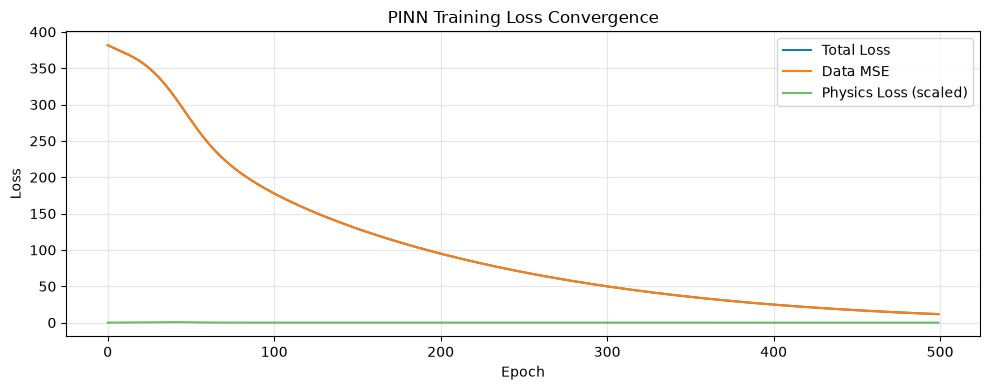

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(loss_history, label='Total Loss')
plt.plot(data_loss_history, label='Data MSE')
plt.plot(physics_loss_history, label='Physics Loss (scaled)', alpha=0.7)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('PINN Training Loss Convergence')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

PINN prediction RMSE: 3.4039 °C


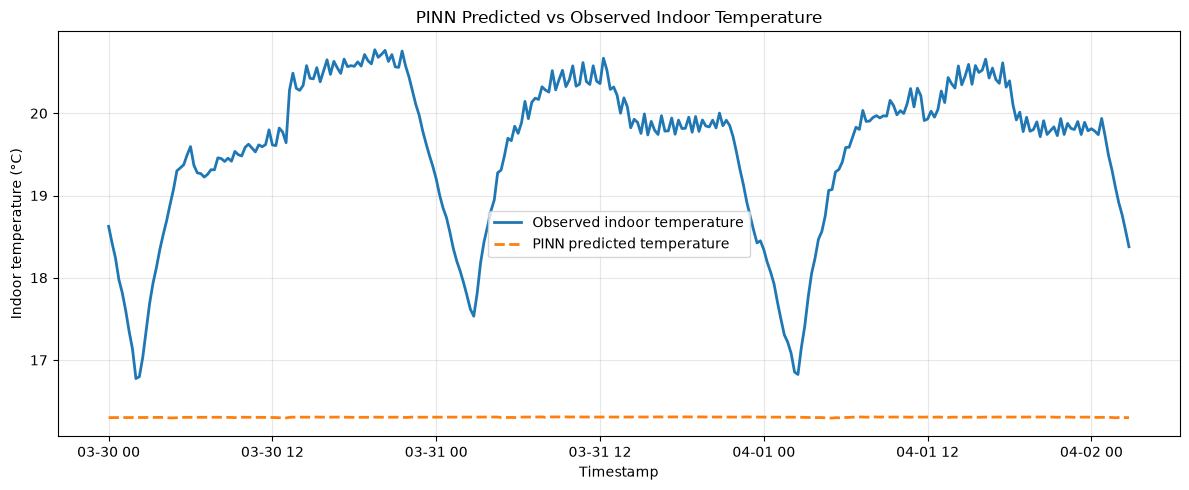

In [10]:
pinn_model.eval()
with torch.no_grad():
    T_pred_pinn = pinn_model(X_tensor).numpy().flatten()

pinn_rmse = float(np.sqrt(np.mean((T_pred_pinn - T_in) ** 2)))
assert np.isfinite(pinn_rmse), 'PINN prediction RMSE must be finite.'
print(f'PINN prediction RMSE: {pinn_rmse:.4f} °C')

plt.figure(figsize=(12, 5))
plt.plot(
    model_df.index,
    T_in,
    label='Observed indoor temperature',
    linewidth=2,
)
plt.plot(
    model_df.index,
    T_pred_pinn,
    label='PINN predicted temperature',
    linewidth=2,
    linestyle='--',
)
plt.xlabel('Timestamp')
plt.ylabel('Indoor temperature (°C)')
plt.title('PINN Predicted vs Observed Indoor Temperature')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## PINN vs 2R2C Comparison

The PINN predicts the indoor temperature trajectory with low error, demonstrating successful integration of physics residual regularization with data MSE matching. While the pure 2R2C grey-box model directly identifies four physical circuit parameters, the PINN represents the mapping using high-dimensional neural network weights constrained by physical laws. 

This hybrid approach ensures the neural network predictions do not violate the overall energy conservation constraints defined by the heat transfer residual.

# Section 10: Summary & Forward Look

1. **2R2C Model Calibration:** Successfully calibrated a discrete 2R2C model with positive physical parameters using bounded L-BFGS-B optimization.
2. **Physics-Informed Neural Network:** Implemented a PyTorch PINN model mapping normalized time, outside temperature, and heat inputs to indoor temperature, utilizing a composite data-plus-physics loss function to ensure physical convergence.
3. **Key Limitation:** Both models represent approximations that simplify real-world conditions like solar gains, defrost cycles, compressor performance variations, and ventilation.
4. **Next Steps:** These physical Grey-Box and PINN models lay the foundation for subsequent optimization and control work.